# CS781 — Phase 4 Court Judgment Prediction (CJPE)
## Model 2 — Full fine-tuning

**Official metric:** binary **Macro-F1**, with per-class precision/recall/F1 tracked.

**Original foundation:** `model2(3).ipynb`, **not** an externally pretrained model. The architecture cell below is copied from the supplied Phase-1 notebook to preserve weights and state-dict keys. It is **not retrained from scratch** in this notebook.

**Adaptation:** Train all Phase-1 backbone parameters plus a hierarchical chunk pooling/classification head.

**Data:** downloaded from `Exploration-Lab/CS-781-Capstone`, under `Phase_4_CJPE/Train/train.json`, `Train/dev.json`, `Test/test.json`. The dev labels are used ONLY for evaluation / best-epoch and decision-threshold selection.

**Kaggle instructions:** Add an authorized HF read token as a Kaggle Secret named `HF`; enable Internet; attach your own Phase-1 **Model 2** checkpoint `pytorch_model.bin` and tokenizer `custom_bpe_scratch.json` as Kaggle inputs. If more than one matching file exists, specify both absolute input paths in the first configuration cell. For KD, supply a *fine-tuned* Phase-4 full teacher checkpoint or let this notebook train one.

**Important:** This code was not run on your actual checkpoint, Hugging Face data, or Kaggle GPU. Do not claim a tested leaderboard score. Your capstone document restricts LLM-authored complete architectures, tuning and analysis; check permitted usage and disclose assistance before using this as an official submission.


**Reliability patch (2026-10-19):** Adds duplicate-ID-safe data audit, input-diversity checks, conditional class rebalancing, full score-boundary development threshold selection, gradient preflight, ROC-AUC and training-probe diagnostics, and FP16 skipped-step-aware scheduling. These are diagnostics/correctness safeguards, not a guarantee of better validation performance. Original Phase-1 architecture and fine-tuning method remain unchanged.


In [4]:
import os, math, random, json, time, zipfile, re, gc, hashlib
from pathlib import Path
from contextlib import nullcontext
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset, WeightedRandomSampler
import torch.utils.checkpoint
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix, classification_report, roc_auc_score
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cuda':
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

MODEL_ID = 2
METHOD = 'full'
REPO_ID = 'Exploration-Lab/CS-781-Capstone'
BASE_CKPT_PATH = '' # optionally set explicit /kaggle/input/.../pytorch_model.bin
BASE_TOKENIZER_PATH = '' # optionally set explicit /kaggle/input/.../custom_bpe_scratch.json
TEACHER_CKPT_PATH = ''  # for KD: optional trained Phase-4 Model-ID FULL checkpoint
TRAIN_TEACHER_IF_MISSING = True
OUTPUT_DIR = Path('/kaggle/working' if Path('/kaggle/working').exists() else './') / f'phase4_cjpe_model{MODEL_ID}_{METHOD}'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# These are the architecture dimensions from YOUR Phase-1 notebooks, not newly trained weights.
VOCAB_SIZE = 32000
N_EMBD = 512 if MODEL_ID == 2 else 560
N_LAYER = 15
N_HEAD = 8
N_KV_HEAD = 4
MODEL_CONTEXT_LENGTH = 2048

# Conservative Kaggle-oriented defaults; these are not validated optimal hyperparameters.
MAX_CHUNKS = 3
MAX_TOKENS_PER_CHUNK = 256
CHARS_PER_VIEW = 2400
BATCH_SIZE = 2
GRAD_ACCUM = 4
EPOCHS = 4
PATIENCE = 2
WARMUP_RATIO = 0.06
GRAD_CLIP_NORM = 1.0
WEIGHT_DECAY = 0.01
LR_BACKBONE = 1.5e-5
LR_ADAPTER = 1.5e-4
LR_HEAD = 2.0e-4
ADAPTER_RANK = 8
ADAPTER_ALPHA = 16
ADAPTER_DROPOUT = 0.05
STUDENT_LAYERS = 8
KD_TEMPERATURE = 2.0
KD_SOFT_WEIGHT = 0.5
NUM_WORKERS = 0
BALANCE_TRAIN_CLASSES = True
BALANCE_RATIO_TRIGGER = 1.5
DIAGNOSTIC_EXAMPLES_PER_CLASS = 16
CHECK_GRADIENTS_BEFORE_TRAINING = True
CHECKPOINT_GRADIENTS = True
AMP_ENABLED = DEVICE.type == 'cuda'
AMP_DTYPE = torch.bfloat16 if AMP_ENABLED and torch.cuda.is_bf16_supported() else torch.float16
print('Device:', DEVICE, '| Model:', MODEL_ID, '| Method:', METHOD)


Device: cuda | Model: 2 | Method: full


## 1 — Official Phase-4 data: cleaning, duplicate consolidation, leakage quarantine and audit

**Important:** identical IDs do not automatically imply duplicate legal examples. Consistent-labeled case passages are grouped; conflicting label IDs are quarantined with an audit. Unicode/HTML controls and whitespace are normalized conservatively; legal wording and case are preserved. No dev/test labels are used in training. All original test IDs are preserved (one prediction per unique case ID). Audits saved under `OUTPUT_DIR/preprocessing_audit`.


In [5]:
import os, math, random, json, time, zipfile, re, gc, hashlib, html, unicodedata
from collections import Counter, defaultdict, OrderedDict
from pathlib import Path

# Phase-4 data integrity policy. Keep case IDs exactly as supplied for submission.
# Labels must be real 0/1 values; ambiguous/conflicting labels are NOT guessed.
# Train / dev groups with inconsistent labels are quarantined and included in the audit.
# Identical IDs with consistent labels are grouped as one case, retaining distinct passages.
AUDIT_DIR = OUTPUT_DIR / 'preprocessing_audit'
AUDIT_DIR.mkdir(parents=True, exist_ok=True)
MAX_PASSAGES_PER_CASE = 12  # longest distinct passages; original text is NOT trimmed
HTML_TAGS = re.compile(r'(?is)</?(?:p|div|br|article|section|li|ul|ol|h[1-6])\b[^>]*>')
CTRL_CHARS = dict.fromkeys(map(ord, '\ufeff\u200b\u200c\u200d\u2060\u00ad'), None)
ALLOWED_LABEL_KEYS = ('label','labels','outcome','judgment','judgement','target')
TEXT_KEYS = ('text','case_text','document','content','sentences')
INVALID_AUDIT_LIMIT = 50

def hf_read_token():
    token = os.environ.get('HF_TOKEN') or os.environ.get('HUGGING_FACE_HUB_TOKEN')
    if token: return token
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret('HF')
    except Exception:
        return None

HF_TOKEN = hf_read_token()
print('Hugging Face authentication:', 'token supplied' if HF_TOKEN else 'anonymous (public-only)')

def hf_json(relative_name):
    try:
        p = hf_hub_download(repo_id=REPO_ID, repo_type='dataset', filename=relative_name, token=HF_TOKEN)
    except Exception as exc:
        raise RuntimeError(f'Cannot retrieve {relative_name} from {REPO_ID}; check Kaggle Internet, the HF secret and dataset permissions.') from exc
    with open(p, 'r', encoding='utf-8-sig') as f:
        return json.load(f)

def as_rows(obj, name):
    # Supported containers: list, {data:[...]}, {examples:[...]},
    # {id:[...], text:[...], label:[...]}, and dictionaries keyed by IDs.
    if isinstance(obj, dict):
        for field in ('data', 'examples', 'records', 'items'):
            if field in obj and isinstance(obj[field], list):
                obj = obj[field]
                break
    if isinstance(obj, dict) and 'id' in obj and isinstance(obj['id'], list):
        columns = {k:v for k,v in obj.items() if isinstance(v,list)}
        size=len(obj['id'])
        if any(len(values)!=size for values in columns.values()):
            raise ValueError(f'{name}: unequal lengths in columnar data')
        obj=[{k:v[j] for k,v in columns.items()} for j in range(size)]
    elif isinstance(obj, dict):
        # Dictionary keyed by ID. Explicit ID in a value takes precedence only if consistent.
        records=[]
        for key, value in obj.items():
            if isinstance(value, dict):
                record=dict(value)
                if 'id' in record and str(record['id']) != str(key):
                    raise ValueError(f'{name}: inconsistent outer key {key!r} and inner ID {record["id"]!r}')
                record['id']=key
            else:
                record={'id':key,'text':value}
            records.append(record)
        obj=records
    if not isinstance(obj,list):
        raise ValueError(f'{name}: expected a list or dictionary; got {type(obj).__name__}')
    return obj

def clean_case_text(obj):
    # Do not lowercase, stem, remove stopwords/statutes, or alter outcome language;
    # the Phase-1 BPE learned natural legal text and decisions are often near the end.
    if isinstance(obj, (list, tuple)):
        parts=[]
        for item in obj:
            if isinstance(item, dict):
                item=next((item[k] for k in TEXT_KEYS if k in item), '')
            if not isinstance(item, str):
                continue
            if item.strip(): parts.append(item)
        obj='\n'.join(parts)
    if not isinstance(obj,str): return ''
    obj=unicodedata.normalize('NFC', obj)
    obj=html.unescape(obj)
    obj=obj.translate(CTRL_CHARS)
    obj=obj.replace('\r\n','\n').replace('\r','\n')
    obj=obj.replace('\u00a0',' ').replace('\u202f',' ')
    obj=HTML_TAGS.sub('\n',obj)
    obj=''.join(ch if ch in ('\n','\t') or (ord(ch)>=32 and ord(ch)!=127) else ' ' for ch in obj)
    obj=re.sub(r'[^\S\n]+',' ',obj)
    obj=re.sub(r' *\n *','\n',obj)
    obj=re.sub(r'\n{3,}','\n\n',obj)
    return obj.strip()

def parse_binary_label(row):
    present=[k for k in ALLOWED_LABEL_KEYS if k in row and row[k] is not None]
    if not present: return None, 'missing_label'
    observed=[]
    for key in present:
        value=row[key]
        if isinstance(value,(list,tuple)) and len(value)==1:
            value=value[0]
        if isinstance(value,bool): return None,'boolean_label'
        if isinstance(value,str):
            value=value.strip()
            if value not in ('0','1'): return None,'invalid_label'
            value=int(value)
        elif isinstance(value,(int,np.integer)):
            value=int(value)
        elif isinstance(value,(float,np.floating)) and math.isfinite(value) and value in (0.0,1.0):
            value=int(value)
        else:
            return None,'invalid_label'
        if value not in (0,1): return None,'invalid_label'
        observed.append(value)
    if len(set(observed))>1: return None,'multiple_label_columns_disagree'
    return observed[0],None

def content_fingerprint(text):
    # Text equality ignoring harmless case and whitespace differences.
    normalized=re.sub(r'\s+',' ',text.casefold()).strip()
    return hashlib.sha256(normalized.encode('utf-8')).hexdigest()

def normalize_records(obj, name, has_labels):
    rows=as_rows(obj,name)
    groups=OrderedDict()
    stats=Counter(raw_rows=len(rows))
    issues=[]
    def issue(reason, index=None, ident=None):
        stats[reason]+=1
        if len(issues)<INVALID_AUDIT_LIMIT:
            issues.append({'reason':reason,'raw_index':index,'id':str(ident) if ident is not None else None})
    for j,row in enumerate(rows):
        if not isinstance(row,dict):
            issue('invalid_record_type',j)
            continue
        ident=row.get('id')
        if isinstance(ident,bool) or not isinstance(ident,(str,int,np.integer)) or not str(ident).strip():
            issue('invalid_or_missing_id',j,ident)
            if name=='test':
                raise ValueError(f'{name}[{j}]: unusable official case ID {ident!r}. Cannot generate valid test submission; see audit/source.')
            continue
        key=str(ident)
        value=next((row[k] for k in TEXT_KEYS if k in row and row[k] is not None),None)
        text_value=clean_case_text(value)
        if not text_value:
            if name!='test':
                issue('empty_text_removed',j,key)
                continue
            issue('empty_test_text_fallback',j,key)
            text_value=' '  # preserves official ID; a valid BPE space token
        if has_labels:
            label,problem=parse_binary_label(row)
            if problem:
                issue(problem,j,key)
                continue
        else:
            label=None
        if key not in groups:
            groups[key]={'id':ident,'labels':set(),'passages':[], 'fingerprints':set(), 'raw_count':0}
        group=groups[key]
        group['raw_count']+=1
        if has_labels: group['labels'].add(label)
        fingerprint=content_fingerprint(text_value)
        if fingerprint in group['fingerprints']:
            issue('repeated_identical_text',j,key)
        else:
            group['passages'].append(text_value)
            group['fingerprints'].add(fingerprint)
    result=[]
    for ident,group in groups.items():
        if has_labels and len(group['labels'])!=1:
            issue('conflicting_labels_quarantined',None,ident)
            continue
        if group['raw_count']>1: stats['ids_with_repeated_rows']+=1
        segments=sorted(group['passages'],key=len,reverse=True)
        # Discard passage copies fully contained inside a larger passage (longer paragraph reused as instance).
        distinct=[]
        for segment in segments:
            if any(segment in longer for longer in distinct):
                stats['contained_passages_removed']+=1
            else:
                distinct.append(segment)
        if len(distinct)>1: stats['ids_with_distinct_passages']+=1
        if len(distinct)>MAX_PASSAGES_PER_CASE:
            issue('passage_limit_exceeded',None,ident)
            distinct=distinct[:MAX_PASSAGES_PER_CASE]
        if not distinct: continue
        item={'id':group['id'], 'text':distinct[0], 'segments':distinct}
        if has_labels: item['label']=next(iter(group['labels']))
        result.append(item)
    stats['unique_records']=len(result)
    stats['class_0']=sum(r.get('label')==0 for r in result)
    stats['class_1']=sum(r.get('label')==1 for r in result)
    stats['empty_test_cases']=sum(r['text']==' ' for r in result) if name=='test' else 0
    audit={'split':name,'counts':dict(stats),'issues_first_50':issues,
           'processing':'group same IDs, remove exact/contained passages, quarantine conflicting labels; preserve original ID and distinct passages'}
    (AUDIT_DIR/f'{name}_initial_audit.json').write_text(json.dumps(audit,indent=2,ensure_ascii=False),encoding='utf-8')
    print(f'{name}: {len(rows):,} raw rows -> {len(result):,} distinct case IDs;',
          'duplicate rows:',stats['ids_with_repeated_rows'],
          'multi-passage IDs:',stats['ids_with_distinct_passages'],
          'conflicting labels:',stats['conflicting_labels_quarantined'])
    if issues: print('  audit counts:',{k:v for k,v in stats.items() if k not in ('raw_rows','unique_records','class_0','class_1')})
    if not result: raise ValueError(f'{name}: no usable records after cleaning. See {AUDIT_DIR}')
    return result

def remove_split_leakage(train,dev,test):
    # Official test has the highest priority, then validation, then training.
    # Detect IDs and identical normalized content across splits; no test labels are examined.
    def get_fps(rows):
        return {content_fingerprint(segment)
                for row in rows for segment in row['segments'] if len(segment.strip())>=60}
    test_ids={str(r['id']) for r in test}; test_fps=get_fps(test)
    dev_clean=[]; dev_removed=[]
    for r in dev:
        why=('id_overlap_test' if str(r['id']) in test_ids else
             'text_overlap_test' if any(content_fingerprint(s) in test_fps for s in r['segments'] if len(s.strip())>=60)
             else None)
        if why: dev_removed.append({'id':str(r['id']),'reason':why})
        else: dev_clean.append(r)
    dev_ids={str(r['id']) for r in dev_clean}
    dev_fps=get_fps(dev_clean)
    train_clean=[]; train_removed=[]
    for r in train:
        key=str(r['id'])
        why=('id_overlap_test' if key in test_ids else
             'id_overlap_dev' if key in dev_ids else
             'text_overlap_test' if any(content_fingerprint(s) in test_fps for s in r['segments'] if len(s.strip())>=60)
             else 'text_overlap_dev' if any(content_fingerprint(s) in dev_fps for s in r['segments'] if len(s.strip())>=60)
             else None)
        if why: train_removed.append({'id':key,'reason':why})
        else: train_clean.append(r)
    audit={'removed_from_train':train_removed,'removed_from_dev':dev_removed,
           'policy':'test IDs/text take priority over dev, which takes priority over train; quarantine lower-priority overlapping cases'}
    (AUDIT_DIR/'cross_split_leakage.json').write_text(json.dumps(audit,indent=2),encoding='utf-8')
    print(f'Cross-split leakage control: excluded {len(train_removed)} train and {len(dev_removed)} dev cases.')
    if train_removed or dev_removed:
        print('  Overlap types train:',dict(Counter(x['reason'] for x in train_removed)),
              '; dev:',dict(Counter(x['reason'] for x in dev_removed)))
    return train_clean,dev_clean

def remove_intra_train_copies(train):
    # Full case-text and additional passages must be identical to count as repeated data
    # under DIFFERENT IDs. Do not remove dev/test IDs: the scorer requires those IDs.
    groups=defaultdict(list)
    for row in train:
        key=tuple(sorted(content_fingerprint(s) for s in row['segments']))
        groups[key].append(row)
    kept=[]; discarded=[]
    for rows in groups.values():
        if len(rows)==1:
            kept.append(rows[0]); continue
        labels={r['label'] for r in rows}
        if len(labels)>1:
            for r in rows:
                discarded.append({'id':str(r['id']),'reason':'identical_case_text_conflicting_labels'})
            continue
        kept.append(rows[0])
        discarded.extend({'id':str(r['id']),'reason':'identical_case_text_duplicate_id'} for r in rows[1:])
    (AUDIT_DIR/'within_train_duplicates.json').write_text(json.dumps(discarded,indent=2),encoding='utf-8')
    if discarded:
        print('Removed',len(discarded),'redundant or contradictorily labeled exact case-text copies within train; details in audit.')
    return kept

train_records=normalize_records(hf_json('Phase_4_CJPE/Train/train.json'),'train',True)
dev_records=normalize_records(hf_json('Phase_4_CJPE/Train/dev.json'),'dev',True)
test_records=normalize_records(hf_json('Phase_4_CJPE/Test/test.json'),'test',False)
train_records,dev_records=remove_split_leakage(train_records,dev_records,test_records)
train_records=remove_intra_train_copies(train_records)
for name,rows in (('train',train_records),('dev',dev_records),('test',test_records)):
    count=Counter(r.get('label') for r in rows)
    chars=[len(r['text']) for r in rows]
    print(f'{name}: {len(rows):,} cases | binary labels:',dict(count) if name!='test' else 'hidden',
          '| case-text chars p50/p95:',np.percentile(chars,[50,95]).astype(int).tolist() if chars else [])
print('IMPORTANT — Training distribution:', dict(Counter(r['label'] for r in train_records)))
print('IMPORTANT — Development distribution:', dict(Counter(r['label'] for r in dev_records)))
if not train_records or not dev_records: raise ValueError('Training or dev empty after cleaning / decontamination. See preprocessing_audit')
if set(r['label'] for r in train_records)!={0,1}:
    raise ValueError('Training split must contain both binary classes after cleaning. See audit; cannot train reliably.')
if set(r['label'] for r in dev_records)!={0,1}:
    raise ValueError('Dev split must contain both binary classes to select a meaningful Macro-F1 threshold. See audit.')
# No raw test labels read; official test ID and relative order are preserved after ID grouping.
assert len({str(r['id']) for r in test_records})==len(test_records)
summary={}
for name,rows in (('train',train_records),('dev',dev_records),('test',test_records)):
    sizes=np.asarray([len(r['text']) for r in rows],dtype=float)
    summary[name]={'cases':len(rows),'class_counts':dict(Counter(str(r.get('label','hidden')) for r in rows)),
                   'length_chars_percentiles':dict(zip(('p10','p50','p90','p99'),np.percentile(sizes,[10,50,90,99]).round().astype(int).tolist())),
                   'multi_passage_cases':sum(len(r['segments'])>1 for r in rows)}
(AUDIT_DIR/'final_data_quality_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
print('Preprocessing audit directory:',AUDIT_DIR)


Hugging Face authentication: token supplied


Phase_4_CJPE/Train/train.json: reconstructing file:   0%|          |  0.00B /  737MB            

Phase_4_CJPE/Train/train.json: downloading bytes:           |  0.00B            

train: 37,387 raw rows -> 32,305 distinct case IDs; duplicate rows: 5082 multi-passage IDs: 0 conflicting labels: 0
  audit counts: {'repeated_identical_text': 5082, 'ids_with_repeated_rows': 5082, 'empty_test_cases': 0}


Phase_4_CJPE/Train/dev.json: reconstructing file:   0%|          |  0.00B / 45.0MB            

Phase_4_CJPE/Train/dev.json: downloading bytes:           |  0.00B            

dev: 1,988 raw rows -> 994 distinct case IDs; duplicate rows: 994 multi-passage IDs: 0 conflicting labels: 0
  audit counts: {'repeated_identical_text': 994, 'ids_with_repeated_rows': 994, 'empty_test_cases': 0}


Phase_4_CJPE/Test/test.json: reconstructing file:   0%|          |  0.00B / 35.3MB            

Phase_4_CJPE/Test/test.json: downloading bytes:           |  0.00B            

test: 1,517 raw rows -> 1,517 distinct case IDs; duplicate rows: 0 multi-passage IDs: 0 conflicting labels: 0
Cross-split leakage control: excluded 0 train and 0 dev cases.
Removed 653 redundant or contradictorily labeled exact case-text copies within train; details in audit.
train: 31,652 cases | binary labels: {0: 18539, 1: 13113} | case-text chars p50/p95: [12055, 53577]
dev: 994 cases | binary labels: {0: 497, 1: 497} | case-text chars p50/p95: [16659, 54214]
test: 1,517 cases | binary labels: hidden | case-text chars p50/p95: [17288, 58036]
IMPORTANT — Training distribution: {0: 18539, 1: 13113}
IMPORTANT — Development distribution: {0: 497, 1: 497}
Preprocessing audit directory: /kaggle/working/phase4_cjpe_model2_full/preprocessing_audit


## 2 — Original Model 2 architecture copied from the uploaded Phase-1 notebook (preserving parameter keys)


In [6]:
# ==========================================
# 4. Custom Architecture (RoPE, RMSNorm, GQA, QK-Norm, Sequential)
# ==========================================
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))
    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

def precompute_freqs_cis(dim, end, theta=10000.0):
    freqs = 1.0 / (theta ** (torch.arange(0, dim, 2)[: (dim // 2)].float() / dim))
    t = torch.arange(end, device=freqs.device)
    freqs_cis = torch.polar(torch.ones_like(torch.outer(t, freqs).float()), torch.outer(t, freqs).float())
    return torch.view_as_real(freqs_cis)

def apply_rotary_emb(xq, xk, freqs_cis):
    xq_ = torch.view_as_complex(xq.float().reshape(*xq.shape[:-1], -1, 2))
    xk_ = torch.view_as_complex(xk.float().reshape(*xk.shape[:-1], -1, 2))
    freqs_cis = freqs_cis.view(1, xq_.shape[1], 1, xq_.shape[-1])
    return torch.view_as_real(xq_ * freqs_cis).flatten(3).type_as(xq), torch.view_as_real(xk_ * freqs_cis).flatten(3).type_as(xk)

class ManualTransformerAttention(nn.Module):
    def __init__(self, head_dim):
        super().__init__()
        self.scale = 1.0 / math.sqrt(head_dim)

    def forward(self, q: torch.Tensor, k: torch.Tensor, v: torch.Tensor, is_causal: bool = True, attention_mask=None):
        B, H, L_q, D = q.shape
        _, _, L_k, _ = k.shape

        k_transposed = k.transpose(-2, -1).contiguous()
        scores = torch.matmul(q, k_transposed) * self.scale

        if is_causal and L_q > 1:
            mask = torch.tril(torch.ones(L_q, L_k, device=q.device)).view(1, 1, L_q, L_k)
            scores = scores.masked_fill(mask == 0, float('-inf'))

        # Apply padding mask for batched inference
        if attention_mask is not None:
            pad_mask = attention_mask.view(attention_mask.size(0), 1, 1, attention_mask.size(1))
            scores = scores.masked_fill(pad_mask == 0, float('-inf'))

        weights = torch.softmax(scores, dim=-1)
        return torch.matmul(weights, v.contiguous())

class GroupedQueryAttention(nn.Module):
    def __init__(self, dim, n_heads, n_kv_heads):
        super().__init__()
        self.n_heads, self.n_kv_heads, self.head_dim = n_heads, n_kv_heads, dim // n_heads

        self.wq = nn.Linear(dim, n_heads * self.head_dim, bias=False)
        self.wk = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
        self.wv = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
        self.wo = nn.Linear(dim, dim, bias=False)

        # QK-Norm layers for stabilization
        self.q_norm = RMSNorm(n_heads * self.head_dim)
        self.k_norm = RMSNorm(n_kv_heads * self.head_dim)

        self.manual_attention = ManualTransformerAttention(self.head_dim)

    def forward(self, x, freqs_cis, kv_cache=None, attention_mask=None):
        B, L, _ = x.shape

        # Apply QK-Norm directly after linear projections
        q = self.q_norm(self.wq(x)).view(B, L, self.n_heads, self.head_dim)
        k = self.k_norm(self.wk(x)).view(B, L, self.n_kv_heads, self.head_dim)
        v = self.wv(x).view(B, L, self.n_kv_heads, self.head_dim)

        q, k = apply_rotary_emb(q, k, freqs_cis)

        if kv_cache is not None:
            k_cache, v_cache = kv_cache
            k = torch.cat([k_cache, k], dim=1) 
            v = torch.cat([v_cache, v], dim=1)
        new_kv_cache = (k, v)

        k_rep = k.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)
        v_rep = v.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)

        out = self.manual_attention(
            q=q.transpose(1, 2), 
            k=k_rep.transpose(1, 2), 
            v=v_rep.transpose(1, 2), 
            is_causal=(L > 1),
            attention_mask=attention_mask
        )

        out = out.transpose(1, 2).contiguous().view(B, L, -1)
        return self.wo(out), new_kv_cache

# class SwiGLU_FFN(nn.Module):
#     def __init__(self, dim, hidden_dim=None):
#         super().__init__()
#         if hidden_dim is None:
#             hidden_dim = int(8 * dim / 3)
#             hidden_dim = 256 * ((hidden_dim + 255) // 256)

#         self.w1 = nn.Linear(dim, hidden_dim, bias=False)
#         self.w2 = nn.Linear(hidden_dim, dim, bias=False)
#         self.w3 = nn.Linear(dim, hidden_dim, bias=False)

#     def forward(self, x):
#         return self.w2(F.silu(self.w1(x)) * self.w3(x))

class CustomTransformerBlock(nn.Module):
    def __init__(self, dim, n_heads, n_kv_heads):
        super().__init__()
        # Restored separate norm layers for sequential architecture
        self.norm1 = RMSNorm(dim)
        self.norm2 = RMSNorm(dim)
        self.attn = GroupedQueryAttention(dim, n_heads, n_kv_heads)

        # Standard Sequential FFN with SiLU (Swish) instead of GELU
        self.ffn = nn.Sequential(
            nn.Linear(dim, dim * 4, bias=False), 
            nn.SiLU(), 
            nn.Linear(dim * 4, dim, bias=False)
        )

    def forward(self, x, freqs_cis, kv_cache=None, attention_mask=None):
        # Sequential Residual Architecture
        attn_out, new_kv_cache = self.attn(self.norm1(x), freqs_cis, kv_cache, attention_mask=attention_mask)
        h = x + attn_out

        out = h + self.ffn(self.norm2(h))

        return out, new_kv_cache

class CustomLegalModel(nn.Module):
    def __init__(self, vocab_size, dim, n_layers, n_heads, n_kv_heads, max_seq_len):
        super().__init__()
        self.tok_embeddings = nn.Embedding(vocab_size, dim)
        self.layers = nn.ModuleList([CustomTransformerBlock(dim, n_heads, n_kv_heads) for _ in range(n_layers)])
        self.norm = RMSNorm(dim)
        self.output = nn.Linear(dim, vocab_size, bias=False)
        self.output.weight = self.tok_embeddings.weight

        self.register_buffer("freqs_cis", precompute_freqs_cis(dim // n_heads, max_seq_len))

    def forward(self, tokens, start_pos=0, kv_caches=None, attention_mask=None):
        B, L = tokens.shape
        freqs_cis = self.freqs_cis[start_pos : start_pos + L].to(tokens.device)
        freqs_cis = torch.view_as_complex(freqs_cis)

        h = self.tok_embeddings(tokens)
        new_caches = []

        for i, layer in enumerate(self.layers):
            cache_i = kv_caches[i] if kv_caches is not None else None
            h, new_cache = layer(h, freqs_cis, kv_cache=cache_i, attention_mask=attention_mask)
            new_caches.append(new_cache)

        return self.output(self.norm(h)), new_caches


## 3 — Original byte-level BPE tokenizer from the uploaded Phase-1 notebook


In [7]:
import re
import json
import os
from collections import Counter, defaultdict

def clean_and_filter(text, ascii_threshold=0.85):
    """
    Cleans text and quickly rejects non-English/heavily foreign text.
    """
    if not text or len(text) < 20: 
        return None

    ascii_count = sum(1 for c in text if ord(c) < 128)
    if (ascii_count / len(text)) < ascii_threshold:
        return None 

    text = re.sub(r'\s+', ' ', text).strip()
    return text

class CustomByteLevelBPE:
    def __init__(self, vocab_size=32000):
        self.vocab_size = vocab_size
        self.merges = {} 

        # Base vocabulary of all 256 individual bytes
        self.vocab = {i: bytes([i]) for i in range(256)}
        self.inverse_vocab = {bytes([i]): i for i in range(256)}
        self.next_id = 256

        # Reserved Special Tokens
        self.pad_id = 0  

    def train(self, texts, target_vocab_size):
        print("Aggregating byte sequence frequencies...")
        word_freqs = Counter()

        # 1. Chunk texts to prevent massive contiguous memory blocks
        for text in texts:
            # Split into words and whitespace blocks to keep sequence lengths small
            chunks = re.findall(r'\S+|\s+', text)
            for chunk in chunks:
                word_freqs[chunk.encode("utf-8")] += 1

        # 2. Drop singletons to massively save RAM
        word_freqs = {w: f for w, f in word_freqs.items() if f > 1}
        print(f"Unique byte sequences to process: {len(word_freqs):,}")

        # Initialize splits: word -> list of byte integers
        splits = {word: list(word) for word in word_freqs}

        # 3. Build fast inverted index
        pair_counts = defaultdict(int)
        pair_to_words = defaultdict(set)

        for word, freq in word_freqs.items():
            split = splits[word]
            for j in range(len(split) - 1):
                pair = (split[j], split[j+1])
                pair_counts[pair] += freq
                pair_to_words[pair].add(word)

        num_merges = target_vocab_size - 256
        print(f"Starting {num_merges} merges...")

        for i in range(num_merges):
            if not pair_counts:
                break

            best_pair = max(pair_counts, key=pair_counts.get)
            new_id = self.next_id

            # Record the merge
            self.merges[best_pair] = new_id
            self.vocab[new_id] = self.vocab[best_pair[0]] + self.vocab[best_pair[1]]
            self.inverse_vocab[self.vocab[new_id]] = new_id

            # 4. FAST INCREMENTAL UPDATE: Only process words containing the best_pair
            words_to_update = list(pair_to_words.get(best_pair, []))

            del pair_counts[best_pair]
            if best_pair in pair_to_words:
                del pair_to_words[best_pair]

            for word in words_to_update:
                split = splits[word]
                freq = word_freqs[word]

                # Remove old pairs associated with this word from global tracking
                for j in range(len(split) - 1):
                    pair = (split[j], split[j+1])
                    if pair != best_pair:
                        pair_counts[pair] -= freq
                        if pair_counts[pair] <= 0:
                            del pair_counts[pair]
                        if word in pair_to_words.get(pair, set()):
                            pair_to_words[pair].remove(word)

                # Execute the merge on this word's internal list
                new_split = []
                j = 0
                while j < len(split):
                    if j < len(split) - 1 and (split[j], split[j+1]) == best_pair:
                        new_split.append(new_id)
                        j += 2
                    else:
                        new_split.append(split[j])
                        j += 1
                splits[word] = new_split

                # Add newly formed pairs back to global tracking
                for j in range(len(new_split) - 1):
                    pair = (new_split[j], new_split[j+1])
                    pair_counts[pair] += freq
                    pair_to_words[pair].add(word)

            self.next_id += 1

            if (i + 1) % 1000 == 0:
                print(f"Merge {i + 1}/{num_merges} completed.")

        print("BPE Training complete!")

    def _get_stats(self, ids):
        counts = Counter()
        for i in range(len(ids) - 1):
            counts[(ids[i], ids[i+1])] += 1
        return counts

    def _merge_vocab(self, ids, pair, idx):
        newids = []
        i = 0
        while i < len(ids):
            if i < len(ids) - 1 and ids[i] == pair[0] and ids[i+1] == pair[1]:
                newids.append(idx)
                i += 2
            else:
                newids.append(ids[i])
                i += 1
        return newids

    def encode(self, text):
        # Chunk text during encoding to prevent \(O(N^2)\) slowdowns on long documents
        chunks = re.findall(r'\S+|\s+', text)
        final_ids = []

        for chunk in chunks:
            ids = list(chunk.encode("utf-8"))
            while len(ids) >= 2:
                stats = self._get_stats(ids)
                pair = min(stats.keys(), key=lambda p: self.merges.get(p, float("inf")))
                if pair not in self.merges:
                    break 
                ids = self._merge_vocab(ids, pair, self.merges[pair])
            final_ids.extend(ids)

        return final_ids

    def decode(self, ids):
        b_text = b"".join(self.vocab[idx] for idx in ids if idx != self.pad_id)
        return b_text.decode("utf-8", errors="replace")

    def get_vocab_size(self):
        return len(self.vocab)

    def save(self, path):
        serializable_merges = {f"{p[0]},{p[1]}": v for p, v in self.merges.items()}
        serializable_vocab = {k: list(v) for k, v in self.vocab.items()}
        data = {
            "vocab_size": self.vocab_size,
            "next_id": self.next_id,
            "merges": serializable_merges,
            "vocab": serializable_vocab
        }
        with open(path, "w", encoding="utf-8") as f:
            json.dump(data, f, ensure_ascii=False)

    def load(self, path):
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)

        self.vocab_size = data["vocab_size"]
        self.next_id = data["next_id"]
        self.merges = {tuple(map(int, k.split(","))): v for k, v in data["merges"].items()}
        self.vocab = {int(k): bytes(v) for k, v in data["vocab"].items()}
        self.inverse_vocab = {v: k for k, v in self.vocab.items()}


## 4 — Strict checkpoint and tokenizer validation (no silent random-base training)


In [8]:
def search_kaggle_inputs(filename):
    roots = [Path('/kaggle/input'), Path('/kaggle/working')]
    found = []
    for root in roots:
        if root.exists():
            found.extend(p for p in root.rglob(filename) if p.is_file())
    return sorted(set(found))

def resolve_asset(explicit, filename, model_id):
    if explicit:
        p = Path(explicit)
        if not p.is_file(): raise FileNotFoundError(f'Configured asset does not exist: {p}')
        return p
    matches = search_kaggle_inputs(filename)
    if not matches:
        raise FileNotFoundError(f'No {filename} found under /kaggle/input or /kaggle/working. '
                                f'Attach your Phase-1 Model {model_id} checkpoint AND tokenizer as Kaggle inputs.')
    if len(matches) == 1:
        return matches[0]
    hints = (f'model{model_id}', f'model_{model_id}', f'm{model_id}-', f'm{model_id}_')
    selected = [p for p in matches if any(hint in str(p).lower() for hint in hints)]
    if len(selected) == 1:
        return selected[0]
    raise RuntimeError(f'Ambiguous {filename} for Model {model_id}. Specify its explicit path in the CONFIG cell. '
                       f'Candidates: {[str(x) for x in matches]}')

base_checkpoint_file = resolve_asset(BASE_CKPT_PATH, 'pytorch_model.bin', MODEL_ID)
tokenizer_file = resolve_asset(BASE_TOKENIZER_PATH, 'custom_bpe_scratch.json', MODEL_ID)
print('Base checkpoint:', base_checkpoint_file)
print('Tokenizer:', tokenizer_file)

# Read the checkpoint saved by your notebook; NOT any off-the-shelf model weights.
def read_base_state(path):
    try:
        saved = torch.load(path, map_location='cpu', weights_only=True)
    except Exception as exc:
        raise RuntimeError(f'Could not load your Phase-1 checkpoint: {path}') from exc
    if not isinstance(saved, dict): raise TypeError('Expected a PyTorch state_dict/checkpoint dictionary')
    if 'model_state_dict' in saved: saved = saved['model_state_dict']
    if 'state_dict' in saved: saved = saved['state_dict']
    if not isinstance(saved, dict): raise TypeError('Checkpoint contains no valid state_dict')
    saved = {k.removeprefix('module.'): v for k, v in saved.items()}
    return saved

base_pretrained_weights = read_base_state(base_checkpoint_file)
expected_embedding_name = 'tok_embeddings.weight' if MODEL_ID == 2 else 'embeddings.weight'
expected = base_pretrained_weights.get(expected_embedding_name)
if expected is None or tuple(expected.shape) != (VOCAB_SIZE, N_EMBD):
    raise RuntimeError('Checkpoint incompatible with original Model '+str(MODEL_ID)+': expected '
                       f'{expected_embedding_name} {(VOCAB_SIZE,N_EMBD)}, found '
                       f'{None if expected is None else tuple(expected.shape)}. Attach the correct Phase-1 weights.')

tokenizer = CustomByteLevelBPE(vocab_size=VOCAB_SIZE)
tokenizer.load(str(tokenizer_file))
assert max(tokenizer.vocab) < VOCAB_SIZE, 'Tokenizer IDs exceed checkpoint embedding table'
assert len(tokenizer.merges) > 0, 'Tokenizer has no trained merges; wrong tokenizer file'
print('Original Phase-1 BPE loaded:', len(tokenizer.vocab), 'entries; merges:', len(tokenizer.merges))


Base checkpoint: /kaggle/input/datasets/baihuwang07/phase1/pytorch_model.bin
Tokenizer: /kaggle/input/datasets/baihuwang07/phase1/custom_bpe_scratch.json
Original Phase-1 BPE loaded: 32000 entries; merges: 31744


## 5 — Distinct LoRA and LoRMA+ adaptation modules


In [9]:
# LoRA: additive low-rank update, y = W0*x + alpha/r * B(A(x)).
class LowRankAdditive(nn.Module):
    def __init__(self, linear, r=8, alpha=16, dropout=0.05):
        super().__init__()
        assert isinstance(linear, nn.Linear)
        self.base = linear
        self.base.requires_grad_(False)
        self.A = nn.Linear(linear.in_features, r, bias=False)
        self.B = nn.Linear(r, linear.out_features, bias=False)
        self.dropout = nn.Dropout(dropout)
        self.scale = alpha / r
        nn.init.kaiming_uniform_(self.A.weight, a=math.sqrt(5))
        nn.init.zeros_(self.B.weight)
    def forward(self, x):
        return self.base(x) + self.scale * self.B(self.A(self.dropout(x)))

# LoRMA+ from Bihany et al. 2025: y=(I+alpha/r*BA) W0*x (multiplicative on W0).
# Critically this uses A/B on the FROZEN PROJECTION OUTPUT, unlike LoRA on input x.
class LowRankMultiplicative(nn.Module):
    def __init__(self, linear, r=8, alpha=16, dropout=0.05):
        super().__init__()
        assert isinstance(linear, nn.Linear)
        self.base = linear
        self.base.requires_grad_(False)
        self.A = nn.Linear(linear.out_features, r, bias=False)
        self.B = nn.Linear(r, linear.out_features, bias=False)
        self.dropout = nn.Dropout(dropout)
        self.scale = alpha / r
        nn.init.kaiming_uniform_(self.A.weight, a=math.sqrt(5))
        nn.init.zeros_(self.B.weight)
    def forward(self, x):
        y0 = self.base(x)
        return y0 + self.scale * self.B(self.A(self.dropout(y0)))


def configure_backbone(backbone, method):
    if method == 'full' or method == 'student_full':
        backbone.requires_grad_(True)
        return 0
    backbone.requires_grad_(False)
    if method not in ('lora', 'lorma'):
        raise ValueError('Unsupported adaptation method '+str(method))
    cls = LowRankAdditive if method == 'lora' else LowRankMultiplicative
    targets = ('wq', 'wk', 'wv', 'wo')
    changed = 0
    for block in backbone.layers:
        for name in targets:
            projection = getattr(block.attn, name)
            setattr(block.attn, name, cls(projection, r=ADAPTER_RANK,
                                         alpha=ADAPTER_ALPHA, dropout=ADAPTER_DROPOUT))
            changed += 1
    assert changed == len(backbone.layers) * len(targets)
    return changed


def construct_base(n_layers=N_LAYER, pretrained_state=None):
    if MODEL_ID == 2:
        base = CustomLegalModel(VOCAB_SIZE, N_EMBD, n_layers, N_HEAD, N_KV_HEAD, MODEL_CONTEXT_LENGTH)
    else:
        base = CustomLegalModel(VOCAB_SIZE, N_EMBD, n_layers, N_HEAD, N_KV_HEAD, MODEL_CONTEXT_LENGTH)
    if pretrained_state is not None:
        if n_layers == N_LAYER:
            base.load_state_dict(pretrained_state, strict=True)
        else:
            # Keep Model-4's alternating standard/bottleneck layers compatible by
            # transferring its first N layers without remapping parities.
            base_state = base.state_dict()
            missing = [k for k,v in base_state.items()
                       if k not in pretrained_state or pretrained_state[k].shape != v.shape]
            if missing:
                raise RuntimeError(f'Student Phase-1 initialization incompatible: {missing[:10]}')
            base.load_state_dict({k:pretrained_state[k] for k in base_state}, strict=True)
    return base


## 6 — Long-document views from cleaned case passages

Beginning, ending and a cue-aware evidence window are selected without reading the label. When source case IDs repeat with distinct passages but consistent labels, passages remain available as context. Documents are not indiscriminately truncated or merged.


In [10]:
# The original BPE is kept intact; do not rewrite/lowercase legal vocabulary.
# Multiple consistent-labeled records of one case can hold distinct passages.
# Select document-level views using case text only (never the label).
CUE = re.compile(r'(?i)\b(?:appeal\s+(?:is\s+)?(?:allowed|dismissed)|petition\s+(?:is\s+)?(?:allowed|dismissed)|'
                 r'we\s+(?:hereby\s+)?(?:allow|dismiss|hold)|accordingly|in\s+the\s+result|'
                 r'order\s+of\s+the\s+court|set\s+aside|final\s+order|in\s+conclusion|'
                 r'for\s+the\s+foregoing\s+reasons|disposed\s+of)\b')

def get_views(row):
    if isinstance(row,str):
        segments=[row]
    else:
        segments=row.get('segments') or [row['text']]
    main=segments[0] or ' '
    n=CHARS_PER_VIEW
    views=[main[:n]]
    if len(main)>n:
        views.append(main[-n:])
    if len(views)<MAX_CHUNKS or MAX_CHUNKS>2:
        candidates=[]
        for si,segment in enumerate(segments):
            if not segment: continue
            if len(segment)<=n:
                center_view=segment
            else:
                matches=[m.start() for m in CUE.finditer(segment) if n//2<=m.start()<len(segment)-n//2]
                center=matches[-1] if matches else len(segment)//2
                begin=max(0,min(len(segment)-n,center-n//2))
                center_view=segment[begin:begin+n]
            # Prefer explicit decision reasoning/evidence in the middle, when present.
            # Added passages can supply evidence absent from the longest case text.
            score=(1 if CUE.search(center_view) else 0, 1 if si==0 else 0, len(center_view))
            candidates.append((score,center_view))
        for _,view in sorted(candidates,key=lambda x:x[0],reverse=True):
            if view and view not in views:
                views.append(view)
            if len(views)>=MAX_CHUNKS: break
    # Keep at least one real, nonempty token in every allocated active window.
    return (list(dict.fromkeys(views)) or [' '])[:MAX_CHUNKS]

class CJPEData(Dataset):
    def __init__(self, rows, tokenizer):
        self.rows = rows
        self.ids, self.masks, self.chunk_masks = [], [], []
        for row in tqdm(rows, desc='Tokenizing Phase-4 cases', leave=False):
            views = get_views(row)
            x = np.zeros((MAX_CHUNKS, MAX_TOKENS_PER_CHUNK), dtype=np.int32)
            mask = np.zeros_like(x, dtype=np.int8)
            cmask = np.zeros(MAX_CHUNKS, dtype=np.int8)
            for i, view in enumerate(views):
                ids = tokenizer.encode(view)
                # Retain the end of conclusion view and start of other views.
                ids = ids[-MAX_TOKENS_PER_CHUNK:] if i == 1 else ids[:MAX_TOKENS_PER_CHUNK]
                if not ids: ids = [32] # byte-level ASCII space, not the reserved zero pad
                x[i, :len(ids)] = ids
                mask[i, :len(ids)] = 1
                cmask[i] = 1
            # Every inactive chunk must still have a valid first key token.
            # Otherwise masking all keys causes NaNs in causal attention,
            # and NaN * 0 would still contaminate hierarchical pooling.
            for unused in range(len(views),MAX_CHUNKS):
                x[unused,0] = 32
                mask[unused,0] = 1
            self.ids.append(x); self.masks.append(mask); self.chunk_masks.append(cmask)
        self.ids = np.stack(self.ids)
        self.masks = np.stack(self.masks)
        self.chunk_masks = np.stack(self.chunk_masks)
    def __len__(self): return len(self.rows)
    def __getitem__(self, i):
        y = self.rows[i].get('label', -1)
        return (torch.from_numpy(self.ids[i].astype(np.int64)),
                torch.from_numpy(self.masks[i].astype(np.int64)),
                torch.from_numpy(self.chunk_masks[i].astype(np.int64)),
                torch.tensor(y, dtype=torch.float32), torch.tensor(i, dtype=torch.long))

train_set = CJPEData(train_records, tokenizer)
dev_set = CJPEData(dev_records, tokenizer)
test_set = CJPEData(test_records, tokenizer)
# Protect Macro-F1 training from an extremely skewed training split.
train_label_values = np.asarray([int(r['label']) for r in train_records], dtype=np.int64)
train_counts = np.bincount(train_label_values, minlength=2)
# Catch tokenizer/input collapse before spending hours fine-tuning.
probe_count = min(48, len(train_set))
probe_ids = np.linspace(0,len(train_set)-1,probe_count,dtype=int).tolist()
unique_token_views = len({train_set.ids[i,0].tobytes() for i in probe_ids})
print('Tokenizer audit: unique first-chunk tensors among',probe_count,'cases =',unique_token_views)
if unique_token_views <= 1:
    raise RuntimeError('All sampled training cases tokenize to identical tensors; check BPE/tokenizer and cleaning')
if np.any(train_counts == 0):
    raise ValueError(f'Both classes required for supervised training: {train_counts.tolist()}')
observed_imbalance = float(train_counts.max() / train_counts.min())
USE_BALANCED_SAMPLER = bool(BALANCE_TRAIN_CLASSES and observed_imbalance >= BALANCE_RATIO_TRIGGER)
if USE_BALANCED_SAMPLER:
    # Expected draw is 50/50 across classes without using development labels.
    # Sample unit is a CASE (not an individual text passage).
    per_sample_weights = 1.0 / train_counts[train_label_values]
    sampler_rng = torch.Generator().manual_seed(SEED)
    train_sampler = WeightedRandomSampler(
        weights=torch.as_tensor(per_sample_weights, dtype=torch.double),
        num_samples=len(train_set), replacement=True, generator=sampler_rng
    )
    train_loader = DataLoader(train_set, batch_size=BATCH_SIZE,
                              sampler=train_sampler, shuffle=False,
                              num_workers=NUM_WORKERS, pin_memory=DEVICE.type=='cuda')
else:
    train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                              num_workers=NUM_WORKERS, pin_memory=DEVICE.type=='cuda')
print('TRAIN LABEL COUNTS (0,1):', train_counts.tolist(),
      '| imbalance ratio:',round(observed_imbalance,2),
      '| balanced case sampler:',USE_BALANCED_SAMPLER)

train_order_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
dev_loader = DataLoader(dev_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)


Tokenizing Phase-4 cases:   0%|          | 0/31652 [00:00<?, ?it/s]

Tokenizing Phase-4 cases:   0%|          | 0/994 [00:00<?, ?it/s]

Tokenizing Phase-4 cases:   0%|          | 0/1517 [00:00<?, ?it/s]

Tokenizer audit: unique first-chunk tensors among 48 cases = 48
TRAIN LABEL COUNTS (0,1): [18539, 13113] | imbalance ratio: 1.41 | balanced case sampler: False


## 7 — Hierarchical classifier over pretrained hidden states (avoids large LM logits)


In [11]:
# Reuses the user's *exact* pretrained transformer layers and norm, without computing
# the ~32k-token LM logits. This saves considerable GPU memory during classification.
class CJPEClassifier(nn.Module):
    def __init__(self, backbone):
        super().__init__()
        self.backbone = backbone
        self.chunk_attention = nn.Linear(N_EMBD, 1)
        self.head = nn.Sequential(nn.LayerNorm(N_EMBD), nn.Linear(N_EMBD, N_EMBD//2),
                                  nn.GELU(), nn.Dropout(0.15), nn.Linear(N_EMBD//2, 1))

    def forward(self, ids, masks, chunk_masks):
        batch, chunks, length = ids.shape
        ids = ids.reshape(batch*chunks, length)
        token_mask = masks.reshape(batch*chunks, length)
        x = self.backbone.tok_embeddings(ids) if MODEL_ID == 2 else self.backbone.embeddings(ids)
        freq = self.backbone.freqs_cis[:length].to(ids.device)
        freq = torch.view_as_complex(freq)
        for block in self.backbone.layers:
            if self.training and CHECKPOINT_GRADIENTS and torch.is_grad_enabled():
                def apply_block(hidden, layer=block):
                    return layer(hidden, freq, kv_cache=None, attention_mask=token_mask)[0]
                x = torch.utils.checkpoint.checkpoint(apply_block, x, use_reentrant=False)
            else:
                x = block(x, freq, kv_cache=None, attention_mask=token_mask)[0]
        x = self.backbone.norm(x)
        token_valid = token_mask.unsqueeze(-1)
        mean_repr = (x*token_valid).sum(dim=1)/token_valid.sum(dim=1).clamp(min=1)
        last_valid_index = (token_mask.sum(dim=1)-1).clamp(min=0)
        last_repr = x[torch.arange(x.size(0), device=x.device), last_valid_index]
        pooled = (mean_repr + last_repr) * 0.5
        pooled = pooled.reshape(batch, chunks, N_EMBD)
        chunk_scores = self.chunk_attention(pooled).squeeze(-1).float()
        chunk_scores = chunk_scores.masked_fill(chunk_masks == 0, -1e4)
        weights = F.softmax(chunk_scores, dim=1).to(pooled.dtype)
        document_repr = (pooled*weights.unsqueeze(-1)).sum(1)
        return self.head(document_repr).squeeze(-1).float()


def new_classifier(method, n_layers=N_LAYER):
    base = construct_base(n_layers, base_pretrained_weights)
    count = configure_backbone(base, method)
    model = CJPEClassifier(base).to(DEVICE)
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print('Adaptation:', method, '| adapted projections:', count,
          '| total parameters:', f'{total:,}', '| trainable:', f'{trainable:,}',
          f'({100*trainable/total:.1f}%)')
    return model


## 8 — Train/evaluate on Macro-F1; threshold selected exclusively on dev


In [12]:
def move_batch(batch):
    return tuple(t.to(DEVICE, non_blocking=True) for t in batch)

def predict_logits(model, loader):
    model.eval()
    ordered = np.zeros(len(loader.dataset), dtype=np.float32)
    with torch.inference_mode():
        for batch in tqdm(loader, desc='Inference', leave=False):
            ids,mask,cmask,_,index = move_batch(batch)
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=AMP_ENABLED):
                logits = model(ids, mask, cmask)
            ordered[index.cpu().numpy()] = logits.float().cpu().numpy()
    return ordered

def sigmoid_np(x):
    x = np.asarray(x, dtype=np.float64)
    return 1/(1+np.exp(-np.clip(x,-40,40)))

def best_threshold(y_true, logits):
    """Exact Macro-F1 threshold sweep over *development* predictions.

    The original grid [0.1, 0.9] cannot work when all scores lie below 0.1.
    Scanning unique observed scores also handles uncalibrated scores correctly.
    This does not fix an ROC-AUC of 0.5: rankings must improve too.
    """
    y_true = np.asarray(y_true, dtype=np.int64)
    probs = sigmoid_np(np.asarray(logits, dtype=np.float64))
    if not np.all(np.isfinite(probs)):
        raise FloatingPointError('Non-finite development probabilities')
    if len(y_true) != len(probs) or len(y_true) == 0:
        raise ValueError('Development predictions/labels are empty or misaligned')
    unique = np.unique(probs)
    # Include both constant-class decisions, all score boundaries, and 0.5.
    thresholds = np.unique(np.r_[unique, np.nextafter(unique[-1], np.inf), 0.5])
    predicted_positive = probs[:, None] >= thresholds[None, :]
    positive = y_true[:, None] == 1
    negative = ~positive
    tp = np.count_nonzero(predicted_positive & positive, axis=0)
    fp = np.count_nonzero(predicted_positive & negative, axis=0)
    fn = np.count_nonzero(~predicted_positive & positive, axis=0)
    tn = np.count_nonzero(~predicted_positive & negative, axis=0)
    f1_pos = np.divide(2*tp, 2*tp+fp+fn, out=np.zeros_like(tp,dtype=float),where=(2*tp+fp+fn)>0)
    f1_neg = np.divide(2*tn, 2*tn+fp+fn, out=np.zeros_like(tn,dtype=float),where=(2*tn+fp+fn)>0)
    scores = (f1_pos + f1_neg)/2.0
    # Favour 0.5 for an EXACT tie, not a particular class by default.
    order = np.lexsort((np.abs(thresholds-0.5), -scores))
    choice = int(order[0])
    return float(thresholds[choice]), float(scores[choice])


def evaluate_dev(model, loader):
    logits = predict_logits(model, loader)
    y = np.asarray([r['label'] for r in dev_records],dtype=np.int64)
    threshold, macro = best_threshold(y, logits)
    pred = (sigmoid_np(logits)>=threshold).astype(int)
    probs = sigmoid_np(logits)
    ranking_auc = float(roc_auc_score(y, logits)) if len(np.unique(y)) == 2 else float('nan')
    metrics = {'macro_f1':float(macro), 'threshold':float(threshold),
               'roc_auc':ranking_auc,
               'predicted_0':int((pred==0).sum()), 'predicted_1':int((pred==1).sum()),
               'prob_min':float(probs.min()), 'prob_max':float(probs.max()),
               'prob_std':float(probs.std()),
               'prob_mean_label0':float(probs[y==0].mean()) if np.any(y==0) else None,
               'prob_mean_label1':float(probs[y==1].mean()) if np.any(y==1) else None,
               'class_0_f1':float(f1_score(y,pred,pos_label=0,average='binary',zero_division=0)),
               'class_1_f1':float(f1_score(y,pred,pos_label=1,average='binary',zero_division=0)),
               'macro_precision':float(precision_score(y,pred,labels=[0,1],average='macro',zero_division=0)),
               'macro_recall':float(recall_score(y,pred,labels=[0,1],average='macro',zero_division=0)),
               'confusion_matrix':confusion_matrix(y,pred,labels=[0,1]).tolist()}
    return metrics, logits

def make_optimizer(model, method):
    base_params = [p for p in model.backbone.parameters() if p.requires_grad]
    head_params = [p for p in list(model.chunk_attention.parameters())+list(model.head.parameters()) if p.requires_grad]
    if not base_params: raise RuntimeError('No trainable backbone/adapter parameters')
    lr = LR_BACKBONE if method in ('full','student_full') else LR_ADAPTER
    opt = torch.optim.AdamW([{'params':base_params, 'lr':lr}, {'params':head_params, 'lr':LR_HEAD}],
                             weight_decay=WEIGHT_DECAY)
    return opt

def save_snapshot(path, model, method, epoch, metrics):
    torch.save({'model_state_dict':{k:v.detach().cpu().clone() for k,v in model.state_dict().items()},
                'method':method,'model_id':MODEL_ID,'epoch':epoch,'metrics':metrics,
                'n_layers':len(model.backbone.layers),
                'phase1_checkpoint':str(base_checkpoint_file),'tokenizer_path':str(tokenizer_file)},path)

def load_snapshot(path, model, expected_method=None):
    obj = torch.load(path,map_location='cpu',weights_only=True)
    if expected_method is not None and obj.get('method') != expected_method:
        raise ValueError(f'Checkpoint method mismatch. Expected {expected_method}, found {obj.get("method")}')
    if obj.get('model_id') != MODEL_ID or obj.get('n_layers') != len(model.backbone.layers):
        raise ValueError('Checkpoint backbone/model size incompatible')
    model.load_state_dict(obj['model_state_dict'],strict=True)
    model.to(DEVICE)
    return obj


def make_balanced_monitor_indices(max_per_class=DIAGNOSTIC_EXAMPLES_PER_CLASS):
    """Fixed small training probe; does not inspect labels outside public train."""
    rng = np.random.default_rng(SEED)
    y = np.asarray([int(row['label']) for row in train_records])
    ids = []
    for label in (0, 1):
        idx = np.flatnonzero(y == label)
        ids.extend(rng.choice(idx, min(max_per_class, len(idx)), replace=False).tolist())
    return ids


def monitor_training_separation(model, indices):
    """Collect probabilities in Subset order (NOT original train indices)."""
    subset = Subset(train_set, indices)
    loader = DataLoader(subset, batch_size=BATCH_SIZE, shuffle=False)
    model.eval()
    out, truth = [], []
    with torch.inference_mode():
        for batch in loader:
            ids, mask, cmask, y, _ = move_batch(batch)
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=AMP_ENABLED):
                logits = model(ids,mask,cmask)
            out.extend(logits.float().cpu().numpy().reshape(-1).tolist())
            truth.extend(y.cpu().numpy().reshape(-1).astype(int).tolist())
    out = np.asarray(out, dtype=np.float64)
    truth = np.asarray(truth, dtype=np.int64)
    return {'train_probe_auc': float(roc_auc_score(truth, out)) if len(np.unique(truth))==2 else None,
            'train_probe_logit_std':float(out.std()),
            'train_probe_positive_logit_mean':float(out[truth==1].mean()) if np.any(truth==1) else None,
            'train_probe_negative_logit_mean':float(out[truth==0].mean()) if np.any(truth==0) else None}


def gradient_preflight(model, criterion, adaptation_method):
    """Catch a disconnected classification head/LoRA gradient before a 90-minute epoch."""
    if not CHECK_GRADIENTS_BEFORE_TRAINING:
        return
    model.train()
    y = np.asarray([int(row['label']) for row in train_records], dtype=np.int64)
    if not np.any(y==0) or not np.any(y==1):
        raise RuntimeError('Training data lacks one class')
    # Use one case per class, each in its own microbatch (GPU-safe).
    chosen = [int(np.flatnonzero(y==0)[0]), int(np.flatnonzero(y==1)[0])]
    model.zero_grad(set_to_none=True)
    debug_logits = []
    # Use GradScaler even in the preflight: FP16 backprop without scaling could
    # underflow the small LoRA gradients and incorrectly report disconnection.
    probe_scaler = torch.amp.GradScaler('cuda', init_scale=256.0,
                                       enabled=(AMP_ENABLED and AMP_DTYPE == torch.float16))
    for idx in chosen:
        ids, mask, cmask, label, _ = train_set[idx]
        ids, mask, cmask = (t.unsqueeze(0).to(DEVICE) for t in (ids,mask,cmask))
        label = label.unsqueeze(0).to(DEVICE)
        # For large checkpoints, using AMP here is necessary to keep the memory footprint realistic.
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=AMP_ENABLED):
            logit = model(ids,mask,cmask)
            loss = criterion(logit.float(),label.float())/len(chosen)
        if not torch.isfinite(loss):
            raise FloatingPointError('Non-finite loss on preflight example')
        probe_scaler.scale(loss).backward()
        debug_logits.append(float(logit.detach().float().item()))
    grad_scale = probe_scaler.get_scale()
    head_norm = sum(float((p.grad.detach().float()/grad_scale).abs().sum()) for n,p in model.named_parameters()
                    if n.startswith('head.') and p.grad is not None)
    adapter_norm = sum(float((p.grad.detach().float()/grad_scale).abs().sum()) for n,p in model.named_parameters()
                       if '.B.weight' in n and p.grad is not None)
    backbone_norm = sum(float((p.grad.detach().float()/grad_scale).abs().sum()) for n,p in model.named_parameters()
                        if n.startswith('backbone.') and p.grad is not None)
    print('PREFLIGHT logits for labels [0,1]:',np.round(debug_logits,5).tolist(),
          '| head gradient abs-sum:',round(head_norm,6),
          '| adapter B gradient abs-sum:',round(adapter_norm,6),
          '| backbone gradient abs-sum:',round(backbone_norm,6))
    model.zero_grad(set_to_none=True)
    if not math.isfinite(head_norm) or head_norm <= 0:
        raise RuntimeError('Classifier head has no finite training gradient; stopping before expensive training')
    if not math.isfinite(backbone_norm) or backbone_norm <= 0:
        raise RuntimeError(f'{adaptation_method} backbone/adapters have no finite gradient; stopping before expensive training')
    if adaptation_method in ('lora', 'lorma') and (not math.isfinite(adapter_norm) or adapter_norm <= 0):
        raise RuntimeError(f'{adaptation_method} adapters have no finite B-gradient; stopping before expensive training')


def fit_classifier(model, method, output_folder, soft_targets=None, soft_weight=0.0, epochs=EPOCHS):
    output_folder = Path(output_folder); output_folder.mkdir(parents=True, exist_ok=True)
    best_path = output_folder/'best_model.pt'
    positive = sum(r['label']==1 for r in train_records)
    negative = len(train_records)-positive
    if positive == 0 or negative == 0:
        raise ValueError('Both classes required for meaningful binary Macro-F1')

    # If train_loader uses a balanced sampler, an additional large pos_weight
    # would count the minority class TWICE and cause a different collapse.
    # Otherwise use the genuine inverse-prevalence correction; no arbitrary cap at 4.
    pos_weight_value = 1.0 if USE_BALANCED_SAMPLER else (negative / positive)
    pos_weight = torch.tensor([pos_weight_value], device=DEVICE, dtype=torch.float32)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    print('TRAIN class 0:',negative,'| class 1:',positive,
          '| balanced sampler:',USE_BALANCED_SAMPLER,
          '| BCE pos_weight:',round(pos_weight_value,4))
    gradient_preflight(model, criterion, method)
    monitor_indices = make_balanced_monitor_indices()

    optimizer = make_optimizer(model,method)
    optimizer_steps = max(1,math.ceil(len(train_loader)/GRAD_ACCUM))*epochs
    warmup_steps = max(1,int(optimizer_steps*WARMUP_RATIO))
    def lr_lambda(step):
        if step<warmup_steps:return max(0.01,(step+1)/warmup_steps)
        q=(step-warmup_steps)/max(1,optimizer_steps-warmup_steps)
        return max(0.05,0.5*(1+math.cos(math.pi*min(1,q))))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer,lr_lambda)
    scaler = torch.amp.GradScaler('cuda', enabled=(AMP_ENABLED and AMP_DTYPE==torch.float16))
    best_score=-1.0; best_auc=-1.0; stale=0; history=[]
    for epoch in range(epochs):
        model.train(); optimizer.zero_grad(set_to_none=True)
        total_loss=torch.zeros((),device=DEVICE,dtype=torch.float32); actual_steps=0; skipped_steps=0
        for step,batch in enumerate(tqdm(train_loader,desc=f'Epoch {epoch+1}/{epochs}',leave=False)):
            ids,mask,cmask,y,index=move_batch(batch)
            with torch.autocast(device_type=DEVICE.type,dtype=AMP_DTYPE,enabled=AMP_ENABLED):
                logits=model(ids,mask,cmask)
                # Keep reduction in FP32 while the large transformer uses mixed precision.
                loss=(1-soft_weight)*criterion(logits.float(),y.float())
                if soft_targets is not None:
                    targets=soft_targets[index.cpu()].to(DEVICE)
                    soft=F.binary_cross_entropy_with_logits(logits.float()/KD_TEMPERATURE,
                            torch.sigmoid(targets.float()/KD_TEMPERATURE),reduction='mean')*KD_TEMPERATURE**2
                    loss=loss+soft_weight*soft
            if not torch.isfinite(loss):
                raise FloatingPointError(f'Non-finite loss at epoch {epoch}, step {step}')
            total_loss += loss.detach().float()  # avoid a GPU-to-CPU .item() synchronization every batch
            scaler.scale(loss/GRAD_ACCUM).backward()
            if (step+1)%GRAD_ACCUM==0 or step+1==len(train_loader):
                scaler.unscale_(optimizer)
                grad_norm=nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad],GRAD_CLIP_NORM)
                if not torch.isfinite(grad_norm):
                    if not scaler.is_enabled():
                        raise FloatingPointError(f'Nonfinite unscaled gradients at epoch {epoch+1}, batch {step+1}')
                    print(f'WARNING: nonfinite gradient at epoch {epoch+1}, batch {step+1}; AMP will skip step')
                previous_scale=scaler.get_scale()
                scaler.step(optimizer)
                scaler.update()
                update_was_skipped = bool(scaler.is_enabled() and scaler.get_scale()<previous_scale)
                optimizer.zero_grad(set_to_none=True)
                if update_was_skipped:
                    skipped_steps+=1
                else:
                    scheduler.step()
                    actual_steps+=1
        if actual_steps == 0:
            raise RuntimeError('Every optimizer step was skipped. Check FP16 overflow; weights never trained.')
        metrics, _ = evaluate_dev(model, dev_loader)
        metrics.update(monitor_training_separation(model, monitor_indices))
        metrics['epoch']=epoch+1
        metrics['mean_train_loss']=float(total_loss.item()/max(1,len(train_loader)))
        metrics['optimizer_steps']=actual_steps
        metrics['skipped_optimizer_steps']=skipped_steps
        history.append(metrics)
        print('epoch',epoch+1,'train loss',round(metrics['mean_train_loss'],4),
              'dev Macro-F1',round(metrics['macro_f1'],4),
              'ROC-AUC',round(metrics['roc_auc'],4),
              'train-probe AUC',round(metrics['train_probe_auc'],4),
              'threshold',round(metrics['threshold'],6),
              'predicted [0,1]',[metrics['predicted_0'],metrics['predicted_1']],
              'probability std',round(metrics['prob_std'],8),
              'skipped/actual optim steps',f'{skipped_steps}/{actual_steps}')
        if (metrics['roc_auc'] <= 0.51 and metrics['prob_std'] < 1e-4):
            print('WARNING: Development scores are nearly constant and ranking AUC is random. '
                  'Inspect training-probe AUC, tokenization, gradients, and label distribution.')
        # When macro-F1 ties, keep a checkpoint that better ranks development cases.
        if (metrics['macro_f1'] > best_score+1e-8 or
            (abs(metrics['macro_f1']-best_score)<=1e-8 and metrics['roc_auc']>best_auc+1e-8)):
            best_score=metrics['macro_f1'];best_auc=metrics['roc_auc'];stale=0
            save_snapshot(best_path,model,method,epoch+1,metrics)
        else:
            stale+=1
            if stale>=PATIENCE:
                print('Early stopping after',epoch+1,'epochs');break
    with open(output_folder/'training_history.json','w') as f:json.dump(history,f,indent=2)
    load_snapshot(best_path,model,method)
    if best_auc <= 0.51:
        print('ALERT: best development ROC-AUC remains approximately random. '
              'A submission can be generated but is not validated as useful. '
              'Check class counts, actual optimizer steps, token diversity and training-probe AUC.')
    return model,history,best_path


## 9 — Experiment execution and best dev checkpoint


In [13]:
model = new_classifier(METHOD)
model, history, best_model_file = fit_classifier(model, METHOD, OUTPUT_DIR)


Adaptation: full | adapted projections: 0 | total parameters: 59,798,274 | trainable: 59,798,274 (100.0%)
TRAIN class 0: 18539 | class 1: 13113 | balanced sampler: False | BCE pos_weight: 1.4138
PREFLIGHT logits for labels [0,1]: [0.1748, -0.00139] | head gradient abs-sum: 360.15932 | adapter B gradient abs-sum: 0 | backbone gradient abs-sum: 453.032254


Epoch 1/4:   0%|          | 0/15826 [00:00<?, ?it/s]

Inference:   0%|          | 0/497 [00:00<?, ?it/s]

epoch 1 train loss 0.8094 dev Macro-F1 0.589 ROC-AUC 0.6163 train-probe AUC 0.6074 threshold 0.410166 predicted [0,1] [575, 419] probability std 0.13415987 skipped/actual optim steps 0/3957


Epoch 2/4:   0%|          | 0/15826 [00:00<?, ?it/s]

Inference:   0%|          | 0/497 [00:00<?, ?it/s]

... (3 outputs left out)

epoch 3 train loss 0.7534 dev Macro-F1 0.5841 ROC-AUC 0.6064 train-probe AUC 0.7188 threshold 0.392337 predicted [0,1] [600, 394] probability std 0.15313231 skipped/actual optim steps 0/3957


Epoch 4/4:   0%|          | 0/15826 [00:00<?, ?it/s]

Inference:   0%|          | 0/497 [00:00<?, ?it/s]

epoch 4 train loss 0.734 dev Macro-F1 0.5746 ROC-AUC 0.6027 train-probe AUC 0.7207 threshold 0.370225 predicted [0,1] [592, 402] probability std 0.17886279 skipped/actual optim steps 0/3957
Early stopping after 4 epochs


## 10 — Official `prediction.json` and `submission.zip`, with strict ID and ZIP validation


Inference:   0%|          | 0/497 [00:00<?, ?it/s]

BEST DEV: Macro-F1: 0.5923688342506973
              precision    recall  f1-score   support

           0       0.58      0.67      0.62       497
           1       0.61      0.52      0.56       497

    accuracy                           0.59       994
   macro avg       0.60      0.59      0.59       994
weighted avg       0.60      0.59      0.59       994

Confusion matrix:
 [[332 165]
 [238 259]]


Inference:   0%|          | 0/759 [00:00<?, ?it/s]

SUBMISSION CREATED: /kaggle/working/phase4_cjpe_model2_full/submission.zip | official cases: 1517
Prediction balance: {0: 869, 1: 648}


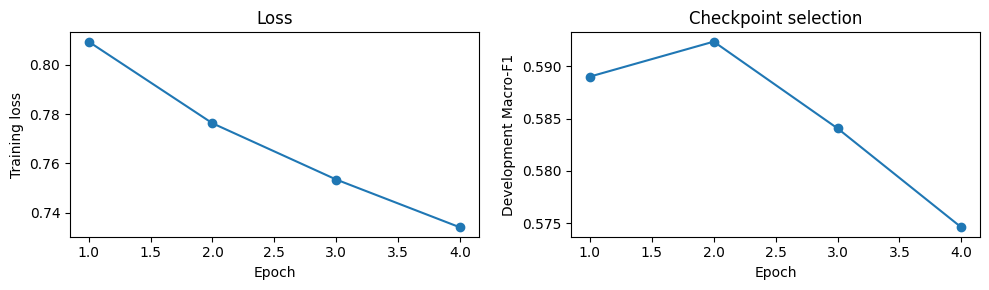

In [14]:
# Save ONLY the best development-selected model and produce the official test-ID list.
final_metadata = torch.load(best_model_file,map_location='cpu',weights_only=True)
threshold = final_metadata['metrics']['threshold']
validation_logits = predict_logits(model,dev_loader)
labels = np.asarray([r['label'] for r in dev_records],dtype=np.int64)
validation_predictions = (sigmoid_np(validation_logits)>=threshold).astype(int)
print('BEST DEV: Macro-F1:',f1_score(labels,validation_predictions,labels=[0,1],average='macro',zero_division=0))
print(classification_report(labels,validation_predictions,labels=[0,1],target_names=['0','1'],zero_division=0))
print('Confusion matrix:\n',confusion_matrix(labels,validation_predictions,labels=[0,1]))

logits = predict_logits(model,test_loader)
test_predictions = (sigmoid_np(logits)>=threshold).astype(int)
payload = [{'id': row['id'], 'pred':int(p)} for row,p in zip(test_records,test_predictions)]
assert len(payload)==len(test_records), 'Wrong prediction count'
assert [p['id'] for p in payload] == [r['id'] for r in test_records], 'Official test IDs/order mismatch'
assert all(set(p)=={'id','pred'} and type(p['pred']) is int and p['pred'] in (0,1) for p in payload)
assert len({str(p['id']) for p in payload})==len(payload), 'Duplicate test IDs'
prediction_file = OUTPUT_DIR/'prediction.json'
with open(prediction_file,'w',encoding='utf-8') as f:
    json.dump(payload,f,ensure_ascii=False,indent=2)
archive = OUTPUT_DIR/'submission.zip'
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as z:
    z.write(prediction_file,arcname='prediction.json')
with zipfile.ZipFile(archive,'r') as z:
    assert z.namelist()==['prediction.json'],z.namelist()
    saved=json.loads(z.read('prediction.json'))
    assert saved==payload, 'Round-trip ZIP/JSON mismatch'
print('SUBMISSION CREATED:',archive,'| official cases:',len(payload))
print('Prediction balance:',{0:int((test_predictions==0).sum()),1:int((test_predictions==1).sum())})

# An inspectable audit of development predictions (not the private-test labels).
with open(OUTPUT_DIR/'dev_predictions.json','w',encoding='utf-8') as f:
    json.dump([{'id':r['id'],'label':r['label'],'pred':int(p),'prob_1':float(q)}
               for r,p,q in zip(dev_records,validation_predictions,sigmoid_np(validation_logits))],f,indent=2)
if history:
    fig,axs=plt.subplots(1,2,figsize=(10,3))
    axs[0].plot([h['epoch'] for h in history],[h['mean_train_loss'] for h in history],marker='o')
    axs[0].set(xlabel='Epoch',ylabel='Training loss',title='Loss')
    axs[1].plot([h['epoch'] for h in history],[h['macro_f1'] for h in history],marker='o')
    axs[1].set(xlabel='Epoch',ylabel='Development Macro-F1',title='Checkpoint selection')
    fig.tight_layout();fig.savefig(OUTPUT_DIR/'training_curves.png',dpi=160);plt.show()
